In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [46]:
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

In [27]:
file_path = Path("C:\\Users\\dhruv\\Downloads\\juypter notebook\\advertising - Copy.csv")
df = pd.read_csv(file_path)

In [28]:
print("First 5 rows are:")
print(df.head())

First 5 rows are:
      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3   12.0
3  151.5   41.3       58.5   16.5
4  180.8   10.8       58.4   17.9


In [29]:
df.shape

(200, 4)

In [30]:
df.size

800

In [31]:
df.info

<bound method DataFrame.info of         TV  Radio  Newspaper  Sales
0    230.1   37.8       69.2   22.1
1     44.5   39.3       45.1   10.4
2     17.2   45.9       69.3   12.0
3    151.5   41.3       58.5   16.5
4    180.8   10.8       58.4   17.9
..     ...    ...        ...    ...
195   38.2    3.7       13.8    7.6
196   94.2    4.9        8.1   14.0
197  177.0    9.3        6.4   14.8
198  283.6   42.0       66.2   25.5
199  232.1    8.6        8.7   18.4

[200 rows x 4 columns]>

In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [33]:
print("Descriptive Statistics")
df.describe()

Descriptive Statistics


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


In [34]:
print(df.isnull())

df.isnull().sum()

        TV  Radio  Newspaper  Sales
0    False  False      False  False
1    False  False      False  False
2    False  False      False  False
3    False  False      False  False
4    False  False      False  False
..     ...    ...        ...    ...
195  False  False      False  False
196  False  False      False  False
197  False  False      False  False
198  False  False      False  False
199  False  False      False  False

[200 rows x 4 columns]


TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [35]:
df.dtypes

TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object

In [36]:
df.corr

<bound method DataFrame.corr of         TV  Radio  Newspaper  Sales
0    230.1   37.8       69.2   22.1
1     44.5   39.3       45.1   10.4
2     17.2   45.9       69.3   12.0
3    151.5   41.3       58.5   16.5
4    180.8   10.8       58.4   17.9
..     ...    ...        ...    ...
195   38.2    3.7       13.8    7.6
196   94.2    4.9        8.1   14.0
197  177.0    9.3        6.4   14.8
198  283.6   42.0       66.2   25.5
199  232.1    8.6        8.7   18.4

[200 rows x 4 columns]>

<Axes: >

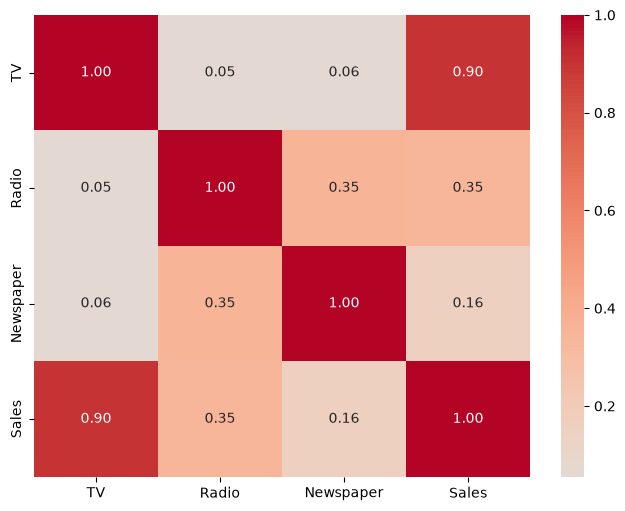

In [37]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', center=0, fmt='.2f')

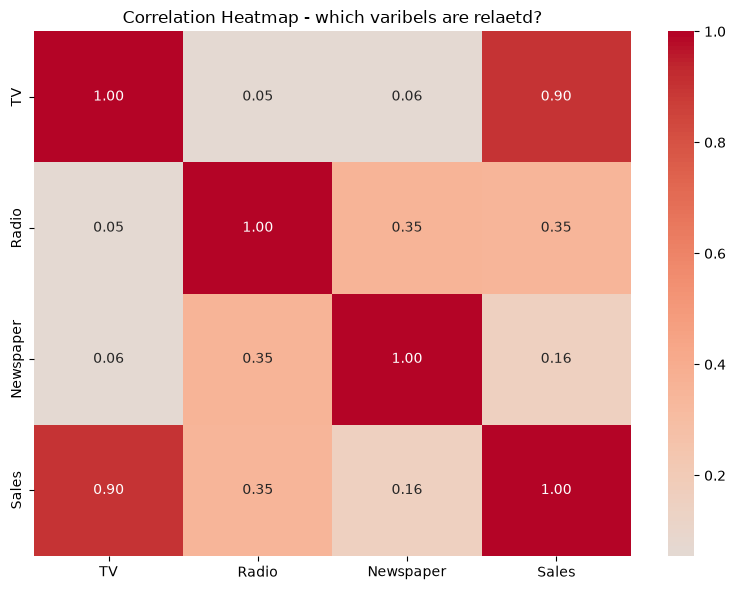

In [38]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation Heatmap - which varibels are relaetd?')
plt.tight_layout()
plt.show()

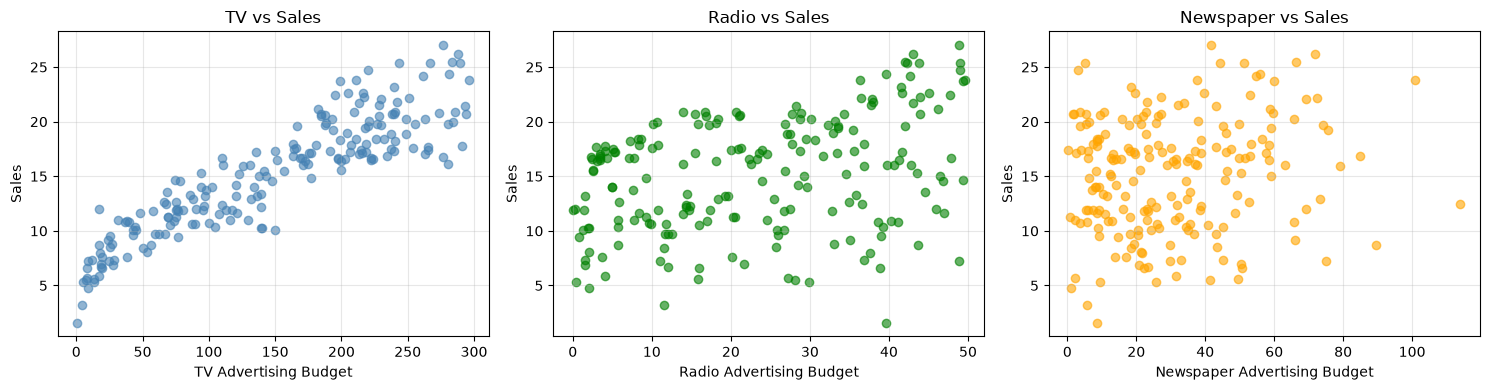

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
 
# Create scatter plot for TV vs Sales
axes[0].scatter(df['TV'], df['Sales'], alpha=0.6, color='steelblue')
axes[0].set_xlabel('TV Advertising Budget')
axes[0].set_ylabel('Sales')
axes[0].set_title('TV vs Sales')
axes[0].grid(True, alpha=0.3)
 
# Create scatter plot for Radio vs Sales
axes[1].scatter(df['Radio'], df['Sales'], alpha=0.6, color='green')
axes[1].set_xlabel('Radio Advertising Budget')
axes[1].set_ylabel('Sales')
axes[1].set_title('Radio vs Sales')
axes[1].grid(True, alpha=0.3)
 
# Create scatter plot for Newspaper vs Sales
axes[2].scatter(df['Newspaper'], df['Sales'], alpha=0.6, color='orange')
axes[2].set_xlabel('Newspaper Advertising Budget')
axes[2].set_ylabel('Sales')
axes[2].set_title('Newspaper vs Sales')
axes[2].grid(True, alpha=0.3)
 
plt.tight_layout()
plt.show()

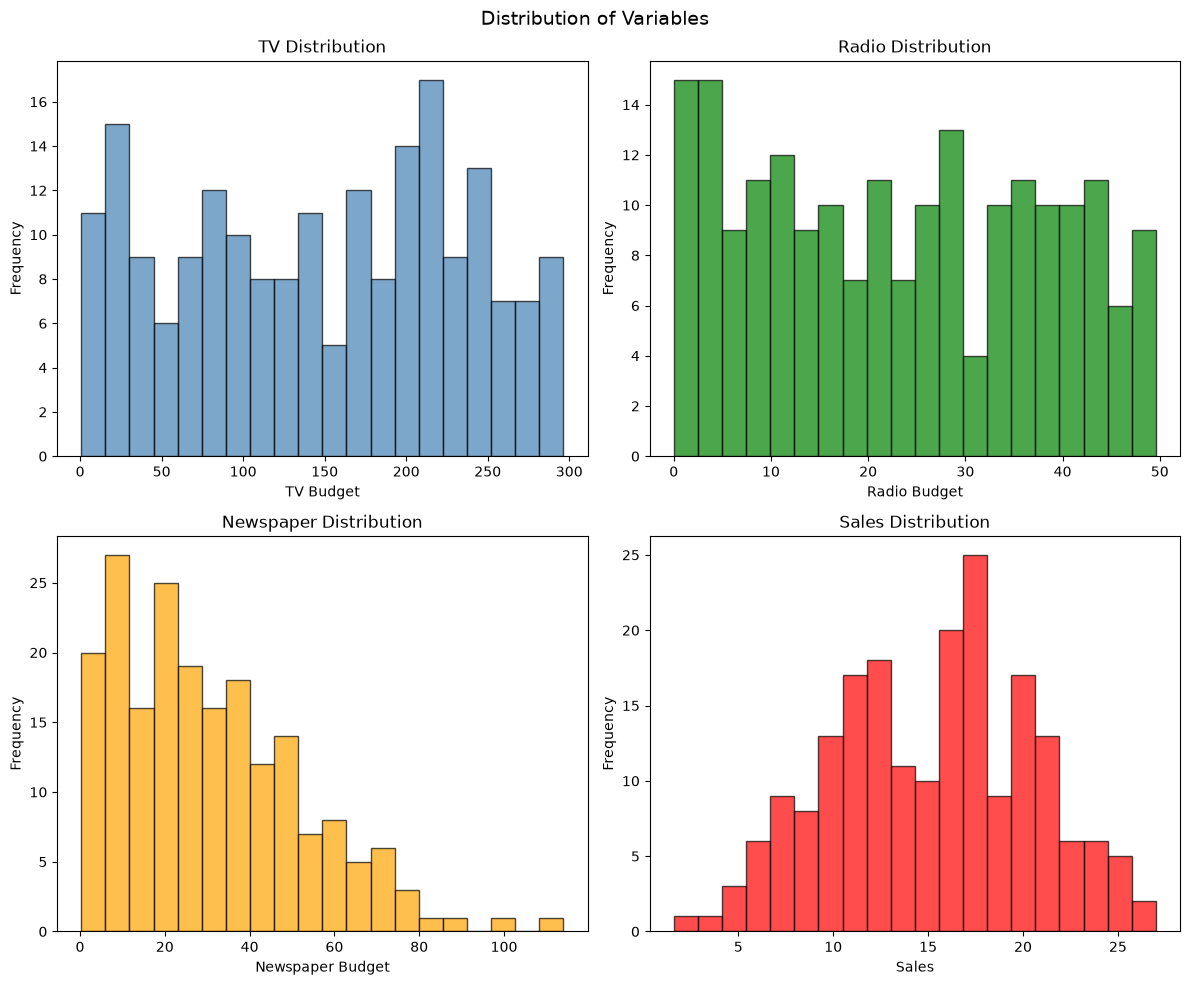

In [40]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Distribution of Variables', fontsize=14)
 
# TV distribution
axes[0, 0].hist(df['TV'], bins=20, edgecolor='black', color='steelblue', alpha=0.7)
axes[0, 0].set_title('TV Distribution')
axes[0, 0].set_xlabel('TV Budget')
axes[0, 0].set_ylabel('Frequency')
 
# Radio distribution
axes[0, 1].hist(df['Radio'], bins=20, edgecolor='black', color='green', alpha=0.7)
axes[0, 1].set_title('Radio Distribution')
axes[0, 1].set_xlabel('Radio Budget')
axes[0, 1].set_ylabel('Frequency')
 
# Newspaper distribution
axes[1, 0].hist(df['Newspaper'], bins=20, edgecolor='black', color='orange', alpha=0.7)
axes[1, 0].set_title('Newspaper Distribution')
axes[1, 0].set_xlabel('Newspaper Budget')
axes[1, 0].set_ylabel('Frequency')
 
# Sales distribution
axes[1, 1].hist(df['Sales'], bins=20, edgecolor='black', color='red', alpha=0.7)
axes[1, 1].set_title('Sales Distribution')
axes[1, 1].set_xlabel('Sales')
axes[1, 1].set_ylabel('Frequency')
 
plt.tight_layout()
plt.show()

In [41]:
correlation = df['TV'].corr(df['Sales'])
 
print(f"Correlation between TV and Sales: {correlation:.4f}")
 
if correlation > 0.8:
    print("→ Very strong positive relationship")
elif correlation > 0.6:
    print("→ Strong positive relationship")
elif correlation > 0.4:
    print("→ Moderate positive relationship")
else:
    print("→ Weak positive relationship")

Correlation between TV and Sales: 0.9012
→ Very strong positive relationship


In [42]:
X = df[['TV']]  
y = df['Sales']
 
print(f"X (TV) shape: {X.shape}")
print(f"y (Sales) shape: {y.shape}")
 
print("\nFirst 5 values of X (TV):")
print(X.head())
 
print("\nFirst 5 values of y (Sales):")
print(y.head())

X (TV) shape: (200, 1)
y (Sales) shape: (200,)

First 5 values of X (TV):
      TV
0  230.1
1   44.5
2   17.2
3  151.5
4  180.8

First 5 values of y (Sales):
0    22.1
1    10.4
2    12.0
3    16.5
4    17.9
Name: Sales, dtype: float64


In [43]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [47]:
model = LinearRegression()

In [48]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.06]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['TV']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,7.007
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [ ]:
"""
slope = 0.06
intercept = 6.975
"""

In [ ]:
sales= 0.06*TV +6.795